In [ ]:
import imageio
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from sklearn.datasets import make_blobs, make_circles, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.autograd.variable import Variable
import numpy as np

Initialize some global parameters

In [ ]:
# Set random seed for reproducibility
np.random.seed(99)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Showing some of the synthetic data generators provided by **Sklearn**

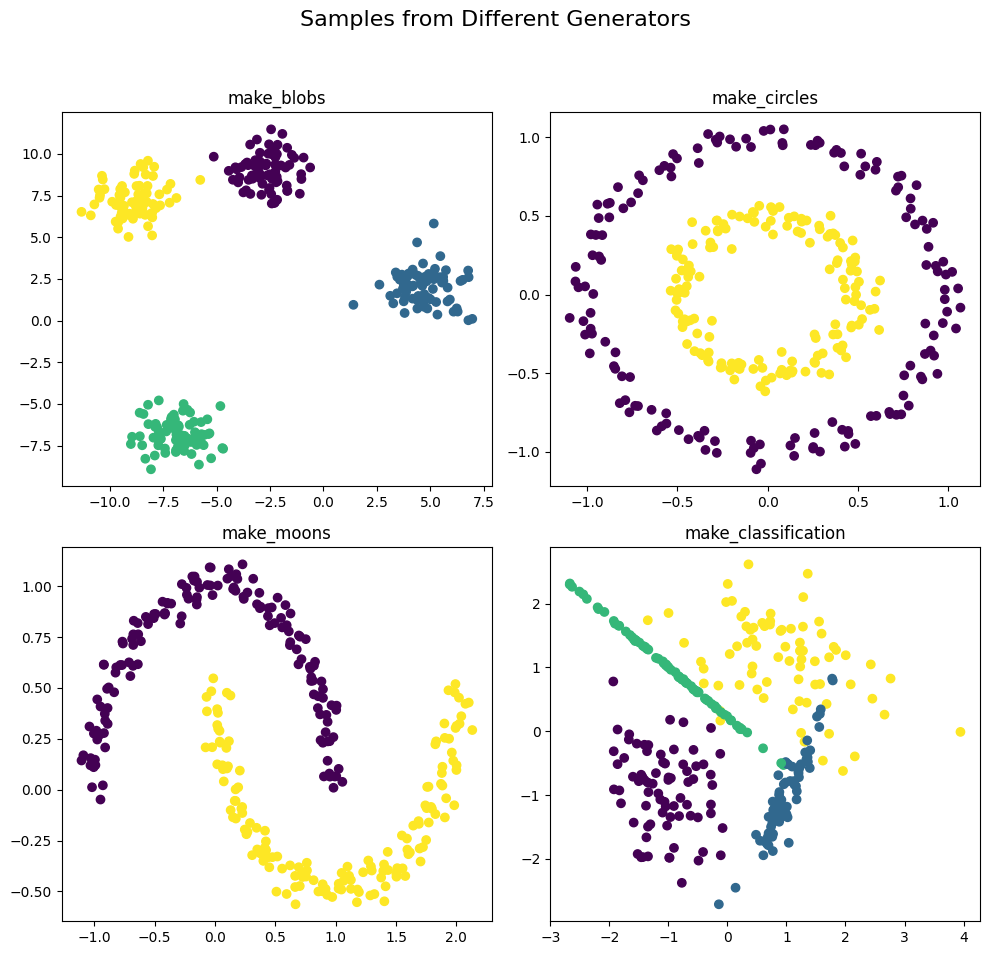

In [ ]:
# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
fig.suptitle('Samples from Different Generators', fontsize=16)

# Generate samples using make_blobs
X_blob, y_blob = make_blobs(n_samples=300, n_features=2, centers=4, random_state=42)
axes[0, 0].scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap='viridis')
axes[0, 0].set_title('make_blobs')

# Generate samples using make_circles
X_circles, y_circles = make_circles(n_samples=300, factor=0.5, noise=0.05, random_state=42)
axes[0, 1].scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles, cmap='viridis')
axes[0, 1].set_title('make_circles')

# Generate samples using make_moons
X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)
axes[1, 0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis')
axes[1, 0].set_title('make_moons')

# Generate samples using make_classification
X_classification, y_classification = make_classification(n_samples=300, n_features=2, n_informative=2,
                                                           n_redundant=0, n_clusters_per_class=1, n_classes=4,
                                                           random_state=42)
axes[1, 1].scatter(X_classification[:, 0], X_classification[:, 1], c=y_classification, cmap='viridis')
axes[1, 1].set_title('make_classification')

# Adjust layout
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# Show the plot
plt.show()


### Dataset creation

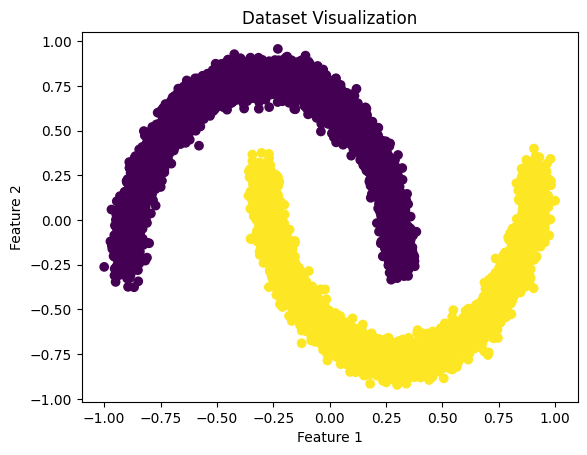

In [ ]:
class SklearnDataset(Dataset):
    def __init__(self, dataset_function, n_samples=300, scale=True, **kwargs):
        """
        PyTorch dataset wrapper for datasets generated by sklearn.datasets functions.

        Parameters:
        - dataset_function: One of the sklearn.datasets functions (e.g., make_blobs, make_circles).
        - n_samples: Number of samples to generate.
        - **kwargs: Additional arguments for the sklearn.datasets function.
        """
        super(SklearnDataset, self).__init__()

        self.data, self.labels = dataset_function(n_samples=n_samples, **kwargs)
        if scale:
            self.data = self.scale_data(self.data)

        self.data = torch.FloatTensor(self.data).to(DEVICE)
        self.labels = torch.LongTensor(self.labels).to(DEVICE)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index], self.labels[index]

    def scale_data(self, data):
        scaler = StandardScaler()
        scaled_data = scaler.fit_transform(data)
        scaled_data = (scaled_data - scaled_data.min()) / (scaled_data.max() - scaled_data.min())  # Scale to [0, 1]
        scaled_data = 2 * scaled_data - 1  # Scale to [-1, 1]
        return scaled_data

def show_data(dataset):
    """
    Visualize the data in the dataset.

    Parameters:
    - dataset: An instance of the SklearnDataset class.
    """
    aux_data = dataset.data.cpu()
    aux_labels = dataset.labels.cpu()
    plt.scatter(aux_data[:, 0], aux_data[:, 1], c=aux_labels, cmap='viridis')
    plt.title('Dataset Visualization')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

# Example usage: Choose a dataset function (e.g., make_blobs, make_circles)
dataset_function = make_blobs
n_samples = 10000
n_classes = 4
dataset = SklearnDataset(dataset_function, n_samples=n_samples, n_features=2, centers=n_classes, random_state=42)

n_samples = 10000
n_classes = 4
dataset_function = make_classification
dataset = SklearnDataset(make_classification, n_samples=n_samples, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1, n_classes=n_classes, random_state=42)

n_samples = 10000
n_classes = 2
dataset_function = make_circles
dataset = SklearnDataset(dataset_function, n_samples=n_samples, factor=0.5, noise=0.05, random_state=42)

n_samples = 10000
n_classes = 2
dataset_function = make_moons
dataset = SklearnDataset(dataset_function, n_samples=n_samples, noise=0.05, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)


Initialize dataset to be used in our traning

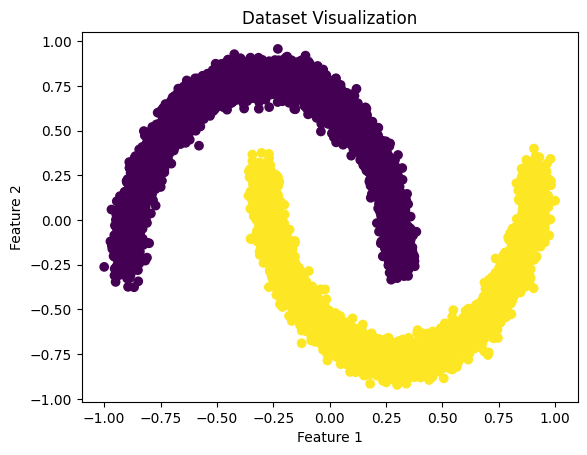

In [ ]:
n_samples = 10000
n_classes = 2
dataset_function = make_moons
dataset = SklearnDataset(dataset_function, n_samples=n_samples, noise=0.05, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)

### Auxiliary functions

To show results

In [ ]:
# Directory to save generated images
save_dir = 'generated_images'
os.makedirs(save_dir, exist_ok=True)

def generate_samples(generator, noise, labels):
    # Concatenate noise and labels properly
    if not labels is None:
      input_data = concat_labels(noise, labels)
    else:
      input_data = noise
    generated_samples = generator(input_data).detach().cpu().numpy()
    return generated_samples

def save_generated_samples(generator, noise, labels, epoch=0, max_epochs=100, save_dir='generated_images', losses=None):
    generated_samples = generate_samples(generator, noise, labels)
    generated_samples = generated_samples

    # Create a subplot figure with 2 rows and 1 column, specifying relative heights
    fig = plt.figure(figsize=(6, 8))

    # Define a gridspec with relative heights (2:1)
    gs = GridSpec(2, 1, height_ratios=[2, 1])

    # Create subplots based on the gridspec
    ax1 = plt.subplot(gs[0])
    ax2 = plt.subplot(gs[1])

    if not labels is None:
      ax1.scatter(generated_samples[:, 0], generated_samples[:, 1], c=labels.cpu().numpy().flatten(), cmap='viridis')
    else:
      ax1.scatter(generated_samples[:, 0], generated_samples[:, 1], cmap='viridis')
    ax1.set_xlim([-1, 1])
    ax1.set_ylim([-1, 1])
    ax1.set_title(f'Generated Samples - Epoch {epoch}')
    ax1.set_xlabel('Feature 1')
    ax1.set_ylabel('Feature 2')

    if not losses is None:
      ax2.plot([0]+losses[0], label='D loss')
      ax2.plot([0]+losses[1], label='G loss')
      ax2.set_xlim([1, max_epochs])
      ax2.set_ylim([0, 2])
      ax2.legend()
      ax2.set_title(f'Loss evolution - {epoch}')
      ax2.set_xlabel('Epochs')
      ax2.set_ylabel('Loss value')



    plt.savefig(os.path.join(save_dir, f'generated_samples_epoch_{epoch}.png'))
    plt.close()


Auxiliary functions required to train the networks

In [ ]:
# Concatenate a tensor of data, i.e., real data or latent space vectors, and labels
def concat_labels(data, labels):
    # Expand the dimensions of labels to match the size of data
    expanded_labels = labels.unsqueeze(1)
    return torch.cat((data, expanded_labels), 1).to(DEVICE)

# Read z from latent space
def read_latent_space(batch_size, noise_dim):
    return torch.randn(batch_size, noise_dim).to(DEVICE)

#  Creates a tensor with the target for real data
def real_data_target(size):
    data = Variable(torch.ones(size, 1)).to(DEVICE)
    return data

#  Creates a tensor with the target for generated data
def fake_data_target(size):
    data = Variable(torch.zeros(size, 1)).to(DEVICE)
    return data

### Conditional GAN architecture creation

Generator

In [ ]:
# Generator model
class Generator(nn.Module):
    def __init__(self, input_size, output_size, hidden_size=32):
        super(Generator, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.tanh(self.fc3(x))
        return x

Discriminator

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, input_size, hidden_size=32):
        super(Discriminator, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

In [ ]:
%rm generated_images/*

### Training

In [ ]:
# Function to train the GAN
def train_gan(generator, discriminator, dataloader, num_epochs=100, lr=0.0002, beta1=0.5, samples_for_evaluation=1000, create_animation=True, save_interval=save_interval):
    # Configuring training
    criterion = nn.BCELoss()
    d_optimizer = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))
    g_optimizer = optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))

    # To generate samples with specified labels
    fixed_noise = read_latent_space(samples_for_evaluation, noise_dim)
    fixed_labels = torch.randint(0, n_classes, (samples_for_evaluation, 1)).float().to(DEVICE)
    fixed_labels = torch.squeeze(fixed_labels)

    # To store loss to show
    disc_loss = list()
    gen_loss = list()

    for epoch in range(num_epochs):
        for real_data, labels in dataloader:
            real_data = Variable(real_data)
            labels = Variable(labels.float())
            batch_size = real_data.size(0)


            # Train discriminator
            d_optimizer.zero_grad()
            d_real_decision = discriminator(concat_labels(real_data, labels))
            d_real_error = criterion(d_real_decision, real_data_target(batch_size))
            d_real_error.backward()

            fake_data = generator(concat_labels(read_latent_space(batch_size, noise_dim), labels)).detach()
            d_fake_decision = discriminator(concat_labels(fake_data, labels))
            d_fake_error = criterion(d_fake_decision, fake_data_target(batch_size))
            d_fake_error.backward()
            d_optimizer.step()

            # Train generator
            g_optimizer.zero_grad()
            fake_data = generator(concat_labels(read_latent_space(batch_size, noise_dim), labels))
            dg_fake_decision = discriminator(concat_labels(fake_data, labels))
            g_error = criterion(dg_fake_decision, real_data_target(batch_size))
            g_error.backward()
            g_optimizer.step()

        if create_animation and epoch % save_interval == 0:
            disc_loss.append(d_real_error.item() + d_fake_error.item())
            gen_loss.append(g_error.item())
            print(f"Epoch {epoch}/{num_epochs}, D loss: {d_real_error.item() + d_fake_error.item()}, G loss: {g_error.item()}")
            save_generated_samples(generator, fixed_noise, fixed_labels, epoch=epoch, losses=(disc_loss, gen_loss), max_epochs=num_epochs)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}/{num_epochs}, D loss: {d_real_error.item() + d_fake_error.item()}, G loss: {g_error.item()}")

In [ ]:
# Prepare data
n_samples = 10000
n_classes = 2
dataset_function = make_moons
dataset = SklearnDataset(dataset_function, n_samples=n_samples, noise=0.05, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)

# Set parameters
input_size = 2  # Features in the dataset
output_size = 2  # Features generated by the generator
hidden_size = 32
noise_dim = 64
batch_size = 100
num_epochs = 100

# Initialize generator and discriminator
generator = Generator(noise_dim+1, output_size, hidden_size).to(DEVICE)
discriminator = Discriminator(input_size+1, hidden_size).to(DEVICE)

save_interval = 1

# Train the GAN
train_gan(generator, discriminator, dataloader, num_epochs=num_epochs, save_interval=save_interval)

image_files = [f'generated_images/generated_samples_epoch_{epoch}.png' for epoch in range(0, num_epochs, save_interval)]

# Load images and create GIF
images = [imageio.imread(image_file) for image_file in image_files]
imageio.mimsave('generated_samples_animation_moons.gif', images, duration=1)

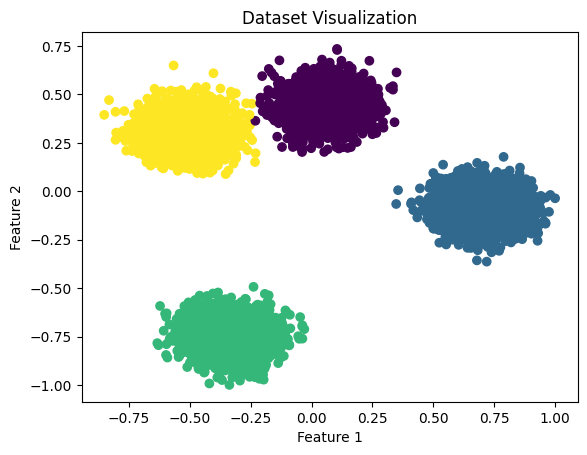

Epoch 0/100, D loss: 1.3624801635742188, G loss: 0.7094249725341797
Epoch 0/100, D loss: 1.3624801635742188, G loss: 0.7094249725341797
Epoch 1/100, D loss: 1.3448580503463745, G loss: 0.7115039825439453
Epoch 2/100, D loss: 1.3513135313987732, G loss: 0.7023073434829712
Epoch 3/100, D loss: 1.3371394276618958, G loss: 0.7091591358184814
Epoch 4/100, D loss: 1.3197610974311829, G loss: 0.7237995266914368
Epoch 5/100, D loss: 1.2783681750297546, G loss: 0.7551828026771545
Epoch 6/100, D loss: 1.2411339282989502, G loss: 0.7829562425613403
Epoch 7/100, D loss: 1.2353432774543762, G loss: 0.8009933233261108
Epoch 8/100, D loss: 1.1850247979164124, G loss: 0.8137103915214539
Epoch 9/100, D loss: 1.1729872226715088, G loss: 0.8432443141937256
Epoch 10/100, D loss: 1.1568397879600525, G loss: 0.9018167853355408
Epoch 10/100, D loss: 1.1568397879600525, G loss: 0.9018167853355408
Epoch 11/100, D loss: 1.1092762351036072, G loss: 0.8878250122070312
Epoch 12/100, D loss: 1.1270509362220764, G l

<ipython-input-26-d7a1a0049c04>:33: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(image_file) for image_file in image_files]


In [ ]:
# Prepare data
dataset_function = make_blobs
n_samples = 10000
n_classes = 4
dataset = SklearnDataset(dataset_function, n_samples=n_samples, n_features=2, centers=n_classes, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)

# Set parameters
input_size = 2  # Features in the dataset
output_size = 2  # Features generated by the generator
hidden_size = 32
noise_dim = 64
batch_size = 100
num_epochs = 100

# Initialize generator and discriminator
generator = Generator(noise_dim+1, output_size, hidden_size).to(DEVICE)
discriminator = Discriminator(input_size+1, hidden_size).to(DEVICE)

save_interval = 1

# Train the GAN
train_gan(generator, discriminator, dataloader, num_epochs=num_epochs, save_interval=save_interval)

image_files = [f'generated_images/generated_samples_epoch_{epoch}.png' for epoch in range(0, num_epochs, save_interval)]

# Load images and create GIF
images = [imageio.imread(image_file) for image_file in image_files]
imageio.mimsave('generated_samples_animation_blobs.gif', images, duration=1)

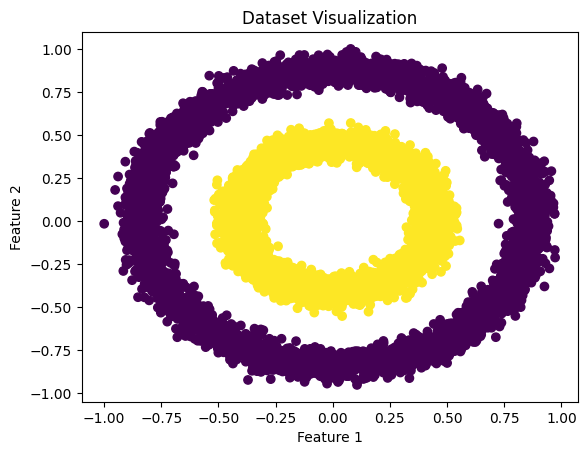

Epoch 0/100, D loss: 1.3789967894554138, G loss: 0.7500054836273193
Epoch 0/100, D loss: 1.3789967894554138, G loss: 0.7500054836273193
Epoch 1/100, D loss: 1.3650641441345215, G loss: 0.7088702321052551
Epoch 2/100, D loss: 1.3018378615379333, G loss: 0.7538602948188782
Epoch 3/100, D loss: 1.5917555093765259, G loss: 0.5293360948562622
Epoch 4/100, D loss: 1.2425415515899658, G loss: 0.8621162176132202
Epoch 5/100, D loss: 1.4363223314285278, G loss: 0.6324946284294128
Epoch 6/100, D loss: 1.3036904335021973, G loss: 0.7381188869476318
Epoch 7/100, D loss: 1.4738625288009644, G loss: 0.6070519685745239
Epoch 8/100, D loss: 1.2738726735115051, G loss: 0.7749261260032654
Epoch 9/100, D loss: 1.446523666381836, G loss: 0.6179165840148926
Epoch 10/100, D loss: 1.305065393447876, G loss: 0.788949728012085
Epoch 10/100, D loss: 1.305065393447876, G loss: 0.788949728012085
Epoch 11/100, D loss: 1.3925426006317139, G loss: 0.6667677164077759
Epoch 12/100, D loss: 1.3164556622505188, G loss: 

<ipython-input-27-b98f6109b192>:33: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(image_file) for image_file in image_files]


In [ ]:
# Prepare data
n_samples = 10000
n_classes = 2
dataset_function = make_circles
dataset = SklearnDataset(dataset_function, n_samples=n_samples, factor=0.5, noise=0.05, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)

# Set parameters
input_size = 2  # Features in the dataset
output_size = 2  # Features generated by the generator
hidden_size = 32
noise_dim = 64
batch_size = 100
num_epochs = 100

# Initialize generator and discriminator
generator = Generator(noise_dim+1, output_size, hidden_size).to(DEVICE)
discriminator = Discriminator(input_size+1, hidden_size).to(DEVICE)

save_interval = 1

# Train the GAN
train_gan(generator, discriminator, dataloader, num_epochs=num_epochs, save_interval=save_interval)

image_files = [f'generated_images/generated_samples_epoch_{epoch}.png' for epoch in range(0, num_epochs, save_interval)]

# Load images and create GIF
images = [imageio.imread(image_file) for image_file in image_files]
imageio.mimsave('generated_samples_animation_circles.gif', images, duration=1)

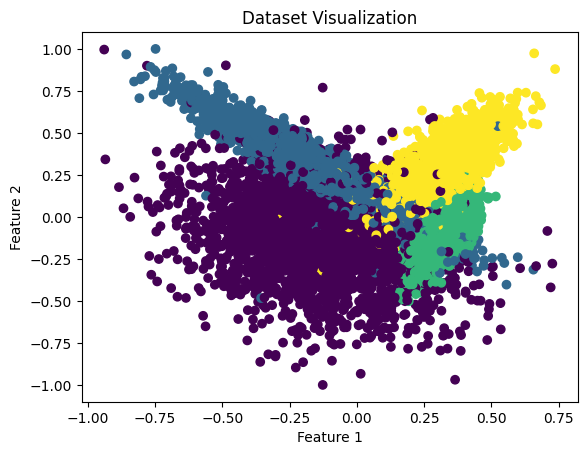

Epoch 0/100, D loss: 1.3758585453033447, G loss: 0.7293182015419006
Epoch 0/100, D loss: 1.3758585453033447, G loss: 0.7293182015419006
Epoch 1/100, D loss: 1.3715618252754211, G loss: 0.7104859948158264
Epoch 2/100, D loss: 1.3773377537727356, G loss: 0.7016763687133789
Epoch 3/100, D loss: 1.369982361793518, G loss: 0.7038260698318481
Epoch 4/100, D loss: 1.3745794296264648, G loss: 0.6987954378128052
Epoch 5/100, D loss: 1.3727904558181763, G loss: 0.700795590877533
Epoch 6/100, D loss: 1.3655157089233398, G loss: 0.7162330746650696
Epoch 7/100, D loss: 1.357197344303131, G loss: 0.7013683915138245
Epoch 8/100, D loss: 1.360843300819397, G loss: 0.7095268964767456
Epoch 9/100, D loss: 1.3603179454803467, G loss: 0.709936797618866
Epoch 10/100, D loss: 1.350452184677124, G loss: 0.7028205990791321
Epoch 10/100, D loss: 1.350452184677124, G loss: 0.7028205990791321
Epoch 11/100, D loss: 1.3440173268318176, G loss: 0.7146086692810059
Epoch 12/100, D loss: 1.3803187012672424, G loss: 0.

<ipython-input-28-5b5948f25118>:33: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(image_file) for image_file in image_files]


In [ ]:
# Prepare data
n_samples = 10000
n_classes = 4
dataset_function = make_classification
dataset = SklearnDataset(make_classification, n_samples=n_samples, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1, n_classes=n_classes, random_state=42)

# Create a PyTorch data loader
batch_size = 100
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Show the data
show_data(dataset)

# Set parameters
input_size = 2  # Features in the dataset
output_size = 2  # Features generated by the generator
hidden_size = 32
noise_dim = 64
batch_size = 100
num_epochs = 100

# Initialize generator and discriminator
generator = Generator(noise_dim+1, output_size, hidden_size).to(DEVICE)
discriminator = Discriminator(input_size+1, hidden_size).to(DEVICE)

save_interval = 1

# Train the GAN
train_gan(generator, discriminator, dataloader, num_epochs=num_epochs, save_interval=save_interval)

image_files = [f'generated_images/generated_samples_epoch_{epoch}.png' for epoch in range(0, num_epochs, save_interval)]

# Load images and create GIF
images = [imageio.imread(image_file) for image_file in image_files]
imageio.mimsave('generated_samples_animation_class.gif', images, duration=1)